In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('titanic_toy.csv')

In [3]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [4]:
from sklearn.model_selection import train_test_split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :2], df.iloc[:, -1], test_size= 0.2, random_state= 42)

In [6]:
X_train.head()

,Age,Fare
331,45.5,28.5000
733,23.0,13.0000
382,32.0,7.9250
704,26.0,7.8542
813,6.0,31.2750


In [7]:
X_train.isna().mean()

Age     0.196629
Fare    0.050562
dtype: float64

In [8]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [9]:
X_train.head()

,Age,Fare,Age_imputed
331,45.5,28.5000,45.5
733,23.0,13.0000,23.0
382,32.0,7.9250,32.0
704,26.0,7.8542,26.0
813,6.0,31.2750,6.0


In [10]:
X_train['Fare_imputed'] = X_train['Fare']
X_test['Fare_imputed'] = X_test['Fare']

In [11]:
X_train.head()

,Age,Fare,Age_imputed,Fare_imputed
331,45.5,28.5000,45.5,28.5000
733,23.0,13.0000,23.0,13.0000
382,32.0,7.9250,32.0,7.9250
704,26.0,7.8542,26.0,7.8542
813,6.0,31.2750,6.0,31.2750


In [12]:
X_train['Age_imputed'][X_train['Age_imputed'].isna()] = X_train['Age'].dropna().sample(X_train['Age_imputed'].isna().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isna()] = X_test['Age'].dropna().sample(X_test['Age_imputed'].isna().sum()).values

C:\Users\gpava\AppData\Local\Temp\ipykernel_5420\4154080129.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['Age_imputed'][X_train['Age_imputed'].isna()] = X_train['Age'].dropna().sample(X_train['Age_imputed'].isna().sum()).value

In [13]:
X_train.head()

,Age,Fare,Age_imputed,Fare_imputed
331,45.5,28.5000,45.5,28.5000
733,23.0,13.0000,23.0,13.0000
382,32.0,7.9250,32.0,7.9250
704,26.0,7.8542,26.0,7.8542
813,6.0,31.2750,6.0,31.2750


In [14]:
X_train['Age_imputed'].isna().sum()

np.int64(0)

In [15]:
print(X_train['Age'].var())
print(X_train['Age_imputed'].var())

210.2517072477438
214.7215360623191


In [16]:
X_train.cov()

,Age,Fare,Age_imputed,Fare_imputed
Age,210.251707,75.481375,210.251707,75.481375
Fare,75.481375,2761.031435,63.707949,2761.031435
Age_imputed,210.251707,63.707949,214.721536,63.707949
Fare_imputed,75.481375,2761.031435,63.707949,2761.031435


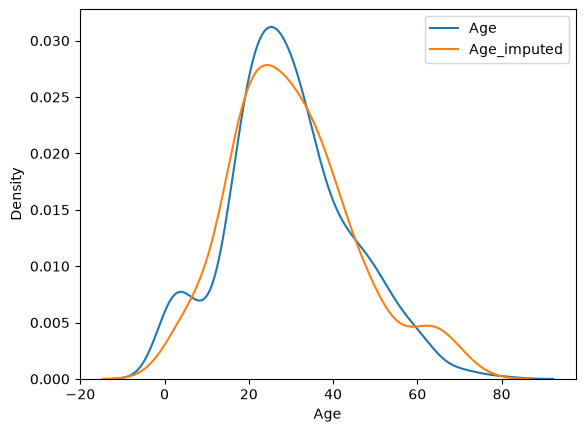

In [17]:
sns.kdeplot(X_train['Age'], label = 'Age')
sns.kdeplot(X_test['Age_imputed'], label = 'Age_imputed')
plt.legend()

In [18]:
X_train['Fare_imputed'][X_train['Fare_imputed'].isna()] = X_train['Fare'].dropna().sample(X_train['Fare_imputed'].isna().sum()).values
X_test['Fare_imputed'][X_test['Fare_imputed'].isna()] = X_test['Fare'].dropna().sample(X_test['Fare_imputed'].isna().sum()).values

C:\Users\gpava\AppData\Local\Temp\ipykernel_5420\2567680699.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['Fare_imputed'][X_train['Fare_imputed'].isna()] = X_train['Fare'].dropna().sample(X_train['Fare_imputed'].isna().sum()).v

In [19]:
print(X_train['Fare'].var())
print(X_train['Fare_imputed'].var())

2761.031434948639
2841.6935933737896


In [20]:
X_train.cov()

,Age,Fare,Age_imputed,Fare_imputed
Age,210.251707,75.481375,210.251707,69.841605
Fare,75.481375,2761.031435,63.707949,2761.031435
Age_imputed,210.251707,63.707949,214.721536,62.228230
Fare_imputed,69.841605,2761.031435,62.228230,2841.693593


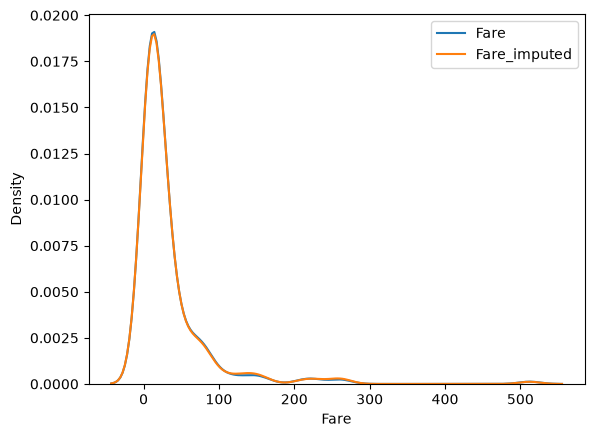

In [21]:
sns.kdeplot(X_train['Fare'], label = 'Fare')
sns.kdeplot(X_train['Fare_imputed'], label = 'Fare_imputed')
plt.legend()

<Axes: >

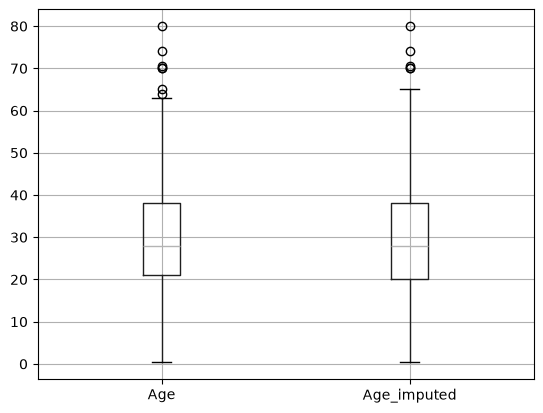

In [22]:
X_train[['Age', 'Age_imputed']].boxplot()

<Axes: >

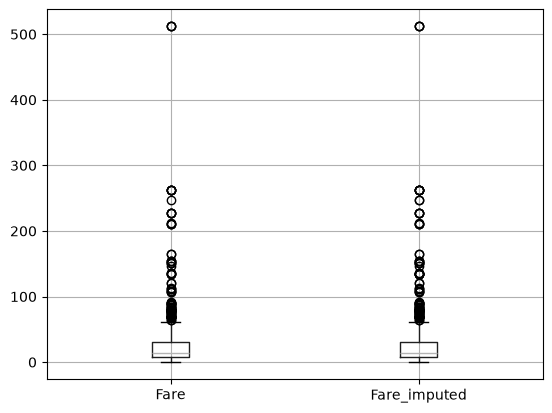

In [23]:
X_train[['Fare', 'Fare_imputed']].boxplot()

In [24]:
df = pd.read_csv('house_train.csv')

In [25]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [26]:
df = df[['FireplaceQu', 'GarageQual', 'SalePrice']]

In [27]:
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [28]:
X_train, X_test , y_train, y_test = train_test_split(df, df.iloc[:, -1], random_state= 42, test_size= 0.2)

In [29]:
X_train.head()

,FireplaceQu,GarageQual,SalePrice
254,NaN,TA,145000
1066,TA,TA,178000
638,NaN,NaN,85000
799,TA,TA,175000
380,Gd,TA,127000


In [30]:
X_train.isna().mean()

FireplaceQu    0.468322
GarageQual     0.054795
SalePrice      0.000000
dtype: float64

In [31]:
X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

In [32]:
X_train.head()

,FireplaceQu,GarageQual,SalePrice,FireplaceQu_imputed,GarageQual_imputed
254,NaN,TA,145000,NaN,TA
1066,TA,TA,178000,TA,TA
638,NaN,NaN,85000,NaN,NaN
799,TA,TA,175000,TA,TA
380,Gd,TA,127000,Gd,TA


In [33]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isna()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isna().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isna()] = X_test['GarageQual'].dropna().sample(X_test['GarageQual'].isna().sum()).values
X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isna()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isna().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isna()] = X_test['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isna().sum()).values

C:\Users\gpava\AppData\Local\Temp\ipykernel_5420\2440451593.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isna()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual']

In [34]:
X_train['GarageQual'].value_counts() / X_train['GarageQual'].dropna().shape[0]

GarageQual
TA    0.951087
Fa    0.032609
Gd    0.011775
Ex    0.002717
Po    0.001812
Name: count, dtype: float64

In [35]:
X_train['GarageQual_imputed'].value_counts() / X_train.shape[0]

GarageQual_imputed
TA    0.952055
Fa    0.031678
Gd    0.011986
Ex    0.002568
Po    0.001712
Name: count, dtype: float64

In [36]:
temp = pd.concat([X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()), X_train['GarageQual_imputed'].value_counts() / len(X_train)], axis= 1)

In [37]:
temp.columns = ['original', 'imputed']

In [38]:
temp

,original,imputed
TA,0.951087,0.952055
Fa,0.032609,0.031678
Gd,0.011775,0.011986
Ex,0.002717,0.002568
Po,0.001812,0.001712


In [39]:
temp2 = pd.concat([
                    X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
                    X_train['FireplaceQu_imputed'].value_counts() / len(X_train)
                ], axis= 1)

In [40]:
temp2.columnsl = temp.columns

C:\Users\gpava\AppData\Local\Temp\ipykernel_5420\456650613.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  temp2.columnsl = temp.columns


In [41]:
temp2

,count,count
Gd,0.491143,0.496575
TA,0.405797,0.403253
Fa,0.043478,0.041952
Ex,0.033816,0.033390
Po,0.025765,0.024829


In [42]:
# trying with the missing indicator

In [43]:
df = pd.read_csv('titanic_toy.csv')

In [44]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [45]:
df = df[['Age', 'Family', 'Survived']]

In [46]:
df.head()

,Age,Family,Survived
0,22.0,1,0
1,38.0,1,1
2,26.0,0,1
3,35.0,1,1
4,35.0,0,0


In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :-1], df.iloc[:, -1], test_size= 0.2, random_state= 42)

In [49]:
X_train.head()

,Age,Family
331,45.5,0
733,23.0,0
382,32.0,0
704,26.0,1
813,6.0,6


In [50]:
X_train.isnull().sum()

Age       140
Family      0
dtype: int64

In [51]:
X_test.isnull().sum()

Age       37
Family     0
dtype: int64

In [52]:
from sklearn.impute import SimpleImputer

In [53]:
si = SimpleImputer()

In [54]:
X_train_trans = si.fit_transform(X_train)
X_test_trans = si.transform(X_test)

In [55]:
from sklearn.linear_model import LogisticRegression

In [56]:
from sklearn.metrics import accuracy_score

In [57]:
lg = LogisticRegression()
lg.fit(X_train_trans, y_train)
accuracy_score(y_test, lg.predict(X_test_trans))

0.5865921787709497

In [58]:
si2 = SimpleImputer(add_indicator= True)

In [59]:
X_train_trans2 = si2.fit_transform(X_train)

In [61]:
X_train_trans2

array([[45.5,  0. ,  0. ],
       [23. ,  0. ,  0. ],
       [32. ,  0. ,  0. ],
       ...,
       [41. ,  2. ,  0. ],
       [14. ,  3. ,  0. ],
       [21. ,  1. ,  0. ]], shape=(712, 3))

In [63]:
X_test_trans2 = si2.transform(X_test)

In [64]:
X_test_trans2

array([[29.49884615,  2.        ,  1.        ],
       [31.        ,  0.        ,  0.        ],
       [20.        ,  0.        ,  0.        ],
       [ 6.        ,  1.        ,  0.        ],
       [14.        ,  1.        ,  0.        ],
       [26.        ,  0.        ,  0.        ],
       [29.49884615,  0.        ,  1.        ],
       [16.        ,  2.        ,  0.        ],
       [16.        ,  0.        ,  0.        ],
       [19.        ,  2.        ,  0.        ],
       [37.        ,  1.        ,  0.        ],
       [44.        ,  0.        ,  0.        ],
       [29.49884615,  4.        ,  1.        ],
       [30.        ,  0.        ,  0.        ],
       [36.        ,  0.        ,  0.        ],
       [16.        ,  1.        ,  0.        ],
       [42.        ,  1.        ,  0.        ],
       [29.49884615,  0.        ,  1.        ],
       [27.        ,  0.        ,  0.        ],
       [47.        ,  0.        ,  0.        ],
       [24.        ,  0.        ,  0.   

In [65]:
lg = LogisticRegression()
lg.fit(X_train_trans2, y_train)
accuracy_score(y_test, lg.predict(X_test_trans2))

0.5865921787709497